# Notebook 3 — Customer Retention and Uplift Modelling

**Project:** Orange Belgium churn and treatment-assignment analysis  
**Goal:** Compare churn-risk targeting with two exploratory treatment-effect ranking approaches.

### Research question
Can observed customer characteristics help rank customers according to their likely benefit from **being assigned** to a retention campaign, beyond simply predicting who will churn?

### Data and interpretation
- **11,896 customers; 180 original columns.** `y=1` means churn; `t=1` denotes retention-campaign assignment, **not confirmed contact or acceptance**.
- Predictors: 160 PCs and 17 nonconstant FACTOR columns (`FACTOR3` is constant).
- The source study reports randomized campaign assignment within a selected high-risk population, but individual campaign allocation probabilities, timing, and campaign identifiers are not available here.
- Estimates and Qini-style summaries are **exploratory**; the assignment mechanism and generalization to customers outside the study population are not fully established.

### Protocol
1. Reproduce the exact row-index split recipe of Notebooks 1–2 (60% train, 20% validation, 20% held-out test; jointly stratified by `t` and `y`).
2. Fit preprocessing and models **only on training data**; compare rankings on validation data.
3. Preserve the historical validation analysis and bootstrap summaries.
4. Evaluate previously fitted strategies **once** on the held-out test data; do not choose a winner after seeing test results.

**Reproducibility:** Place `Orange Belgium_churn_uplift_anonymized.csv` in `data/raw/` or the project root, and run cells from top to bottom. Requires Python with `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `catboost`, `statsmodels`, and Jupyter/IPython. Existing outputs were retained from the supplied notebook; the CSV was not provided for a fresh end-to-end execution here.


**Repository note:** Notebook 3 is an exploratory uplift analysis using the 60/20/20 locked split from Notebooks 1–2. The published comparison of test strategies is descriptive; neither learners' causal policy benefit nor superiority was established. The pre-existing saved notebook outputs are historical outputs; execute all cells locally with the original dataset for verification.

## 1. Inspect the original dataset

Confirm population size, campaign assignment distribution, and observed churn rates. The raw difference is not by itself a causal effect.

In [1]:

# ============================================================
# PROJECT 3 - NOTEBOOK 3
# STEP 1A: LOAD AND INSPECT RETENTION DATA
# ============================================================

import pandas as pd

# Locate the CSV when running from either the project root or notebooks/.
from pathlib import Path
csv_name = "Orange Belgium_churn_uplift_anonymized.csv"
search_roots = [Path.cwd(), Path.cwd().parent]
candidates = [root / folder / csv_name for root in search_roots
              for folder in (Path("data/raw"), Path("."))]
csv_path = next((p for p in candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Orange Belgium CSV not found. Put it in data/raw/ or the project root."
    )
df = pd.read_csv(csv_path)
assert df.shape == (11896, 180), "Unexpected source dataset dimensions."
assert set(df["y"].unique()) <= {0, 1}
assert set(df["t"].unique()) <= {0, 1}
print("Source CSV:", csv_path)

# Check the number of rows and columns.
print("Dataset shape:", df.shape)

# Check treatment assignment.
print("\nTREATMENT DISTRIBUTION")
print(df["t"].value_counts().sort_index())

# Check churn outcomes.
print("\nCHURN DISTRIBUTION")
print(df["y"].value_counts().sort_index())

# Examine churn outcomes within each treatment group.
print("\nTREATMENT AND CHURN")
print(pd.crosstab(df["t"], df["y"]))

# Calculate churn rates for each treatment group.
print("\nCHURN RATES BY TREATMENT")
print(df.groupby("t")["y"].mean().round(4))


Dataset shape: (11896, 180)

TREATMENT DISTRIBUTION
t
0    2886
1    9010
Name: count, dtype: int64

CHURN DISTRIBUTION
y
0    11488
1      408
Name: count, dtype: int64

TREATMENT AND CHURN
y     0    1
t           
0  2781  105
1  8707  303

CHURN RATES BY TREATMENT
t
0    0.0364
1    0.0336
Name: y, dtype: float64


## 2. Numerical covariate balance

Use standardized mean differences (SMDs) to screen for observed differences; |SMD| ≥ 0.10 is a descriptive flag, not proof of confounding.

In [2]:

# ============================================================
# PROJECT 3 - NOTEBOOK 3
# STEP 1B: CHECK NUMERICAL FEATURE BALANCE
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. IDENTIFY THE NUMERICAL PREDICTORS
# ------------------------------------------------------------

# Our anonymized numerical predictors are PC1 to PC160.
pc_columns = [f"PC{i}" for i in range(1, 161)]

# Separate treatment and control observations.
control_group = df[df["t"] == 0]
treatment_group = df[df["t"] == 1]

# ------------------------------------------------------------
# 2. CALCULATE STANDARDIZED MEAN DIFFERENCES
# ------------------------------------------------------------

balance_results = []

for column in pc_columns:

    # Calculate the mean for both groups.
    control_mean = control_group[column].mean()
    treatment_mean = treatment_group[column].mean()

    # Calculate standard deviations.
    control_sd = control_group[column].std()
    treatment_sd = treatment_group[column].std()

    # Calculate the pooled standard deviation.
    pooled_sd = np.sqrt(
        (control_sd**2 + treatment_sd**2) / 2
    )

    # Calculate standardized mean difference.
    if pooled_sd > 0:
        smd = (treatment_mean - control_mean) / pooled_sd
    else:
        smd = np.nan

    balance_results.append({
        "Feature": column,
        "SMD": smd,
        "Absolute_SMD": abs(smd)
    })

# Create a comparison DataFrame.
balance_summary = pd.DataFrame(balance_results)

# ------------------------------------------------------------
# 3. SUMMARIZE GROUP BALANCE
# ------------------------------------------------------------

print("NUMERICAL FEATURE BALANCE")
print("-" * 55)

print("Features examined:", len(balance_summary))

print(
    "Features with |SMD| >= 0.10:",
    (balance_summary["Absolute_SMD"] >= 0.10).sum()
)

print(
    "Maximum absolute SMD:",
    round(balance_summary["Absolute_SMD"].max(), 4)
)

# Show the ten most imbalanced numerical predictors.
print("\nTOP 10 NUMERICAL FEATURES BY ABSOLUTE SMD")

display(
    balance_summary
    .sort_values("Absolute_SMD", ascending=False)
    .head(10)
    .round(4)
)


NUMERICAL FEATURE BALANCE
-------------------------------------------------------
Features examined: 160
Features with |SMD| >= 0.10: 7
Maximum absolute SMD: 0.2197

TOP 10 NUMERICAL FEATURES BY ABSOLUTE SMD


,Feature,SMD,Absolute_SMD
7,PC8,-0.2197,0.2197
27,PC28,0.1678,0.1678
0,PC1,0.1284,0.1284
1,PC2,0.1108,0.1108
6,PC7,0.1108,0.1108
11,PC12,0.1064,0.1064
3,PC4,-0.1046,0.1046
131,PC132,-0.0990,0.0990
19,PC20,-0.0980,0.0980
18,PC19,0.0873,0.0873


## 3. Categorical covariate balance

Compare category proportions between treatment arms; the 5-percentage-point threshold is an exploratory screening rule.

In [3]:

# ============================================================
# NOTEBOOK 3 - STEP 1C: CATEGORICAL FEATURE BALANCE
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. IDENTIFY CATEGORICAL FEATURES
# ------------------------------------------------------------

factor_columns = [f"FACTOR{i}" for i in range(1, 19)]

# Exclude FACTOR3 because it is constant.
factor_columns = [
    col for col in factor_columns if col != "FACTOR3"
]

categorical_balance_results = []

# ------------------------------------------------------------
# 2. COMPARE CATEGORY PROPORTIONS
# ------------------------------------------------------------

for column in factor_columns:

    # Percentage distribution within each treatment group.
    proportions = pd.crosstab(
        df[column].fillna("Missing"),
        df["t"],
        normalize="columns"
    )

    # Difference in percentage points between groups.
    differences = (
        proportions[1] - proportions[0]
    ).abs() * 100

    # Record the largest observed category difference.
    categorical_balance_results.append({
        "Feature": column,
        "Categories": len(proportions),
        "Max_Difference_pp": differences.max()
    })

# ------------------------------------------------------------
# 3. CREATE SUMMARY
# ------------------------------------------------------------

categorical_balance_summary = pd.DataFrame(
    categorical_balance_results
)

categorical_balance_summary = (
    categorical_balance_summary
    .sort_values(
        "Max_Difference_pp",
        ascending=False
    )
)

print("CATEGORICAL FEATURE BALANCE")
print("-" * 55)

print(
    "Features examined:",
    len(categorical_balance_summary)
)

print(
    "Features with maximum category difference >= 5 pp:",
    (
        categorical_balance_summary[
            "Max_Difference_pp"
        ] >= 5
    ).sum()
)

print("\nTOP 10 CATEGORICAL FEATURES BY IMBALANCE")

display(
    categorical_balance_summary
    .head(10)
    .round(4)
)


CATEGORICAL FEATURE BALANCE
-------------------------------------------------------
Features examined: 17
Features with maximum category difference >= 5 pp: 3

TOP 10 CATEGORICAL FEATURES BY IMBALANCE


,Feature,Categories,Max_Difference_pp
16,FACTOR18,7,17.6198
2,FACTOR4,20,12.1420
1,FACTOR2,12,6.2488
4,FACTOR6,20,4.6211
10,FACTOR12,3,4.0550
14,FACTOR16,17,3.7360
5,FACTOR7,3,2.7976
11,FACTOR13,12,2.1672
3,FACTOR5,4,2.1416
8,FACTOR10,4,2.1164


## 4. Reproduce the protected split and inspect treatment propensity

Recreate the **same index-based splitting procedure** used in the previous notebooks. Fit propensity preprocessing only on training data and evaluate on validation data.

In [4]:

# ============================================================
# NOTEBOOK 3 - STEP 1D: PROPENSITY MODEL DIAGNOSTIC
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. PREPARE THE PREDICTORS AND TREATMENT ASSIGNMENT
# ------------------------------------------------------------

# Remove the churn outcome, treatment assignment,
# and constant feature from the predictor matrix.
X = df.drop(columns=["y", "t", "FACTOR3"])

y = df["y"]
t = df["t"]

# ------------------------------------------------------------
# 2. RECREATE OUR EXISTING DATA SPLIT
# ------------------------------------------------------------

# Stratify jointly on treatment and churn outcome.
# This maintains the proportions of all four groups.
joint_labels = (
    t.astype(str) + "_" + y.astype(str)
)

# Notebook 1 and Notebook 2 split *row indices* with these exact rules.
# Keeping their index order ensures equivalent train/validation/test records.
all_indices = df.index.to_numpy()
train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.40,
    random_state=42,
    stratify=joint_labels
)
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=joint_labels.loc[temp_indices]
)

X_train_prop = X.loc[train_indices].copy()
X_val_prop = X.loc[val_indices].copy()
X_test_prop = X.loc[test_indices].copy()
t_train_prop = t.loc[train_indices].copy()
t_val_prop = t.loc[val_indices].copy()
t_test_prop = t.loc[test_indices].copy()

# Structural verification: disjoint observations and preserved alignment.
assert (len(X_train_prop), len(X_val_prop), len(X_test_prop)) == (7137, 2379, 2380)
assert X_train_prop.shape[1] == 177
assert not set(train_indices) & set(val_indices)
assert not set(train_indices) & set(test_indices)
assert not set(val_indices) & set(test_indices)
assert len(set(train_indices) | set(val_indices) | set(test_indices)) == len(df)
assert X_train_prop.index.equals(t_train_prop.index)
assert X_val_prop.index.equals(t_val_prop.index)
assert X_test_prop.index.equals(t_test_prop.index)
print("Split integrity: PASS (Notebook 1/2 index split recipe)")

# ------------------------------------------------------------
# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------

numerical_features = X_train_prop.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_prop.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# ------------------------------------------------------------
# 4. CREATE THE PREPROCESSING PIPELINE
# ------------------------------------------------------------

propensity_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

propensity_model = Pipeline(
    steps=[
        ("preprocessing", propensity_preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

# ------------------------------------------------------------
# 5. TRAIN ON TRAINING DATA ONLY
# ------------------------------------------------------------

propensity_model.fit(
    X_train_prop,
    t_train_prop
)

# ------------------------------------------------------------
# 6. EVALUATE TREATMENT ASSIGNMENT PREDICTION
# ------------------------------------------------------------

propensity_val = propensity_model.predict_proba(
    X_val_prop
)[:, 1]

propensity_auc = roc_auc_score(
    t_val_prop,
    propensity_val
)

print("PROPENSITY MODEL DIAGNOSTIC")
print("-" * 55)

print("Training customers:", len(X_train_prop))
print("Validation customers:", len(X_val_prop))

print(
    "Validation ROC-AUC:",
    round(propensity_auc, 4)
)

print(
    "Minimum predicted propensity:",
    round(propensity_val.min(), 4)
)

print(
    "Maximum predicted propensity:",
    round(propensity_val.max(), 4)
)

# Compare treatment and control score distributions.
propensity_summary = pd.DataFrame({
    "Treatment": t_val_prop.to_numpy(),
    "Propensity": propensity_val
})

print("\nPROPENSITY DISTRIBUTION BY GROUP")

display(
    propensity_summary
    .groupby("Treatment")["Propensity"]
    .describe()
    .round(4)
)


PROPENSITY MODEL DIAGNOSTIC
-------------------------------------------------------
Training customers: 7137
Validation customers: 2379
Validation ROC-AUC: 0.636
Minimum predicted propensity: 0.0542
Maximum predicted propensity: 0.9999

PROPENSITY DISTRIBUTION BY GROUP


,count,mean,std,min,25%,50%,75%,max
Treatment,,,,,,,,
0,577.0,0.7076,0.1414,0.0542,0.6144,0.7270,0.8121,0.9873
1,1802.0,0.7722,0.1302,0.0966,0.6953,0.7908,0.8696,0.9999


## 5. Propensity-score overlap

Inspect whether each treatment group contains customers with similar estimated propensities. Overlap alone cannot establish randomization, exchangeability, or positivity.

PROPENSITY OVERLAP DIAGNOSTIC
-------------------------------------------------------


,Customers,Within_0_10_to_0_90,Above_0_95
Treatment,,,
0,577,94.11,1.56
1,1802,83.91,4.55


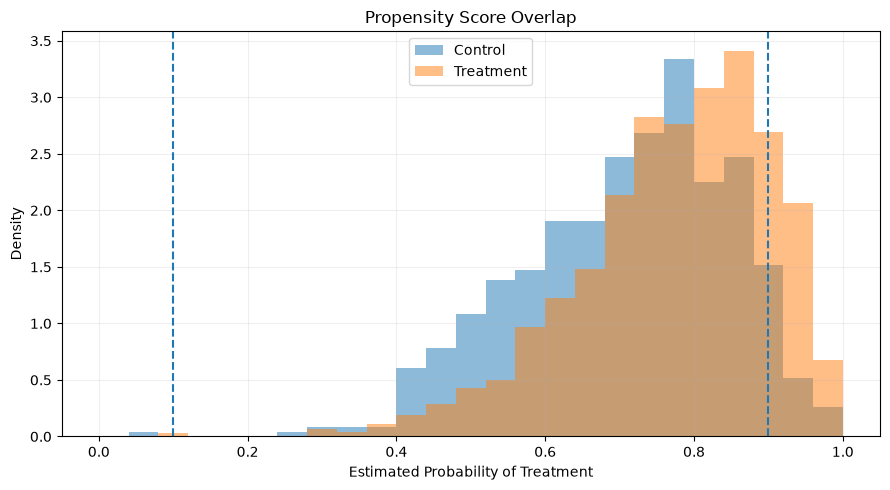

In [5]:

# ============================================================
# NOTEBOOK 3 - STEP 1E: PROPENSITY SCORE OVERLAP
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINE THE COMMON PROPENSITY RANGE
# ------------------------------------------------------------

# This range is a diagnostic guideline, not a universal rule.
lower_bound = 0.10
upper_bound = 0.90

# Create a copy of our validation propensity results.
overlap_data = propensity_summary.copy()

# Identify customers within the diagnostic range.
overlap_data["Within_Range"] = (
    overlap_data["Propensity"].between(
        lower_bound,
        upper_bound
    )
)

# Identify customers with extremely high propensity.
overlap_data["Above_095"] = (
    overlap_data["Propensity"] > 0.95
)

# ------------------------------------------------------------
# 2. SUMMARIZE OVERLAP BY TREATMENT GROUP
# ------------------------------------------------------------

overlap_results = (
    overlap_data
    .groupby("Treatment")
    .agg(
        Customers=("Propensity", "size"),
        Within_0_10_to_0_90=("Within_Range", "mean"),
        Above_0_95=("Above_095", "mean")
    )
)

# Convert proportions into percentages.
overlap_results[
    ["Within_0_10_to_0_90", "Above_0_95"]
] *= 100

print("PROPENSITY OVERLAP DIAGNOSTIC")
print("-" * 55)

display(overlap_results.round(2))

# ------------------------------------------------------------
# 3. VISUALIZE PROPENSITY DISTRIBUTIONS
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for group, label in [
    (0, "Control"),
    (1, "Treatment")
]:

    scores = overlap_data.loc[
        overlap_data["Treatment"] == group,
        "Propensity"
    ]

    plt.hist(
        scores,
        bins=25,
        range=(0, 1),
        density=True,
        alpha=0.5,
        label=label
    )

plt.axvline(0.10, linestyle="--")
plt.axvline(0.90, linestyle="--")

plt.title("Propensity Score Overlap")
plt.xlabel("Estimated Probability of Treatment")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Treatment assignment and causal scope

The dataset marks **assignment** to a retention campaign (`t`), not confirmed successful contact. Published study descriptions characterize campaign allocation as randomized within a preselected high-risk customer cohort. Nevertheless, our file does not verify individual or campaign-specific treatment probabilities or provide all assignment details.

In this sample, **7/160 numerical** features have |SMD| ≥ 0.10, and **3/17 categorical** factors show at least one category difference ≥ 5 percentage points. A treatment propensity classifier reached validation ROC-AUC **0.6360**. These descriptive imbalances may occur even after random assignment and cannot alone establish the allocation mechanism.

Consequently, the analysis reports conditional outcome predictions, observed assignment-group contrasts, and **exploratory** uplift ranking. Causal interpretation depends on the original experiment's assignment probabilities, consistency, positivity, and whether assignment was correctly measured. Effects relate at most to the campaign-eligible research population, not all telecommunications customers.


## 6. T-Learner: two outcome models

Fit one CatBoost model among controls and one among treated customers. Positive uplift score is defined as predicted control churn minus predicted treated churn; these are not observed individual causal effects.

In [6]:

# ============================================================
# NOTEBOOK 3 - STEP 1G: TRAIN A CATBOOST T-LEARNER
# ============================================================

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# 1. USE OUR EXISTING TRAINING AND VALIDATION SPLITS
# ------------------------------------------------------------

# Recover churn outcomes using the same customer indices.
y_train_uplift = y.loc[X_train_prop.index]
y_val_uplift = y.loc[X_val_prop.index]

# Create copies of our predictor datasets.
X_train_uplift = X_train_prop.copy()
X_val_uplift = X_val_prop.copy()

# Convert categorical predictors to strings for CatBoost.
for column in categorical_features:
    X_train_uplift[column] = (
        X_train_uplift[column].astype(str)
    )
    X_val_uplift[column] = (
        X_val_uplift[column].astype(str)
    )

# ------------------------------------------------------------
# 2. IDENTIFY TREATMENT AND CONTROL TRAINING CUSTOMERS
# ------------------------------------------------------------

control_mask = (t_train_prop == 0).to_numpy()
treatment_mask = (t_train_prop == 1).to_numpy()

print("T-LEARNER TRAINING GROUPS")
print("-" * 55)

print("Control customers:", control_mask.sum())
print("Treatment customers:", treatment_mask.sum())

print(
    "Control churners:",
    y_train_uplift.to_numpy()[control_mask].sum()
)

print(
    "Treatment churners:",
    y_train_uplift.to_numpy()[treatment_mask].sum()
)

# ------------------------------------------------------------
# 3. CREATE TWO INDEPENDENT CATBOOST MODELS
# ------------------------------------------------------------

# Model 0 learns churn outcomes for control customers.
control_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=42,
    verbose=False
)

# Model 1 learns churn outcomes for treated customers.
treatment_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=42,
    verbose=False
)

# ------------------------------------------------------------
# 4. TRAIN EACH MODEL ON ITS CORRESPONDING GROUP
# ------------------------------------------------------------

control_model.fit(
    X_train_uplift.loc[t_train_prop == 0],
    y_train_uplift.loc[t_train_prop == 0],
    cat_features=categorical_features
)

treatment_model.fit(
    X_train_uplift.loc[t_train_prop == 1],
    y_train_uplift.loc[t_train_prop == 1],
    cat_features=categorical_features
)

print("\nBoth T-Learner models trained successfully.")

# ------------------------------------------------------------
# 5. PREDICT BOTH POTENTIAL CHURN RISKS
# ------------------------------------------------------------

# Predict churn risk WITHOUT campaign assignment.
p_control = control_model.predict_proba(
    X_val_uplift
)[:, 1]

# Predict churn risk WITH campaign assignment.
p_treatment = treatment_model.predict_proba(
    X_val_uplift
)[:, 1]

# ------------------------------------------------------------
# 6. ESTIMATE RETENTION UPLIFT
# ------------------------------------------------------------

# Positive uplift = model-estimated reduction in churn risk.
# The two probabilities are not verified as calibrated counterfactual risks.
uplift_scores = p_control - p_treatment

uplift_results = pd.DataFrame({
    "Predicted_Churn_Control": p_control,
    "Predicted_Churn_Treatment": p_treatment,
    "Estimated_Uplift": uplift_scores
})

# ------------------------------------------------------------
# 7. SUMMARIZE THE UPLIFT ESTIMATES
# ------------------------------------------------------------

print("\nT-LEARNER UPLIFT SUMMARY")
print("-" * 55)

display(
    uplift_results.describe().round(4)
)

print(
    "\nCustomers with positive estimated uplift:",
    int((uplift_scores > 0).sum())
)

print(
    "Customers with negative estimated uplift:",
    int((uplift_scores < 0).sum())
)

print(
    "Mean estimated uplift:",
    round(uplift_scores.mean(), 5)
)


T-LEARNER TRAINING GROUPS
-------------------------------------------------------
Control customers: 1731
Treatment customers: 5406
Control churners: 63
Treatment churners: 182

Both T-Learner models trained successfully.

T-LEARNER UPLIFT SUMMARY
-------------------------------------------------------


,Predicted_Churn_Control,Predicted_Churn_Treatment,Estimated_Uplift
count,2379.0000,2379.0000,2379.0000
mean,0.0076,0.0114,-0.0038
std,0.0174,0.0240,0.0252
min,0.0001,0.0001,-0.4428
25%,0.0010,0.0014,-0.0039
50%,0.0025,0.0034,-0.0006
75%,0.0068,0.0115,0.0008
max,0.3534,0.4636,0.3127



Customers with positive estimated uplift: 896
Customers with negative estimated uplift: 1483
Mean estimated uplift: -0.00377


## 7. Validation uplift by ranking fraction

Inspect cumulative top-ranked subsets, with both observed treatment and control rates. Groups overlap and may have small event counts.

In [7]:

# ============================================================
# NOTEBOOK 3 - STEP 1H: VALIDATION UPLIFT EVALUATION
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. COMBINE VALIDATION RESULTS
# ------------------------------------------------------------

evaluation = pd.DataFrame({
    "Treatment": t_val_prop.to_numpy(),
    "Actual_Churn": y_val_uplift.to_numpy(),
    "Estimated_Uplift": uplift_scores
})

# Sort customers from highest to lowest predicted uplift.
evaluation = evaluation.sort_values(
    "Estimated_Uplift",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. EVALUATE DIFFERENT TOP-RANKED CUSTOMER GROUPS
# ------------------------------------------------------------

# Examine the top 20%, 40%, 60%, 80%, and all customers.
fractions = [0.20, 0.40, 0.60, 0.80, 1.00]

results = []

for fraction in fractions:

    # Select the highest-ranked customers.
    n = int(round(len(evaluation) * fraction))
    selected = evaluation.iloc[:n]

    # Separate actual treatment and control customers.
    control = selected[selected["Treatment"] == 0]
    treated = selected[selected["Treatment"] == 1]

    # Calculate observed churn rates.
    control_rate = control["Actual_Churn"].mean()
    treatment_rate = treated["Actual_Churn"].mean()

    # Observed difference:
    # Positive means lower churn in the treated group.
    observed_difference = control_rate - treatment_rate

    results.append({
        "Top_Percent": int(fraction * 100),
        "Customers": n,
        "Control_N": len(control),
        "Treatment_N": len(treated),
        "Control_Churners": int(control["Actual_Churn"].sum()),
        "Treatment_Churners": int(treated["Actual_Churn"].sum()),
        "Control_Rate": control_rate,
        "Treatment_Rate": treatment_rate,
        "Observed_Difference_pp": observed_difference * 100
    })

# ------------------------------------------------------------
# 3. DISPLAY THE EVALUATION TABLE
# ------------------------------------------------------------

uplift_evaluation = pd.DataFrame(results)

print("T-LEARNER VALIDATION UPLIFT EVALUATION")
print("-" * 65)

display(uplift_evaluation.round(4))


T-LEARNER VALIDATION UPLIFT EVALUATION
-----------------------------------------------------------------


,Top_Percent,Customers,Control_N,Treatment_N,Control_Churners,Treatment_Churners,Control_Rate,Treatment_Rate,Observed_Difference_pp
0,20,476,94,382,7,18,0.0745,0.0471,2.7348
1,40,952,213,739,8,20,0.0376,0.0271,1.0495
2,60,1427,327,1100,8,24,0.0245,0.0218,0.2647
3,80,1903,442,1461,8,37,0.0181,0.0253,-0.7226
4,100,2379,577,1802,21,61,0.0364,0.0339,0.2544


## 8. Uncertainty for the T-Learner top 20%

Use a Newcombe interval for a **difference of observed proportions**, conditional on the selected subgroup. It is not a confidence interval for a fully learned individual causal effect.

In [8]:

# ============================================================
# NOTEBOOK 3 - STEP 1I: CONFIDENCE INTERVAL FOR TOP 20%
# ============================================================

import numpy as np
from statsmodels.stats.proportion import (
    confint_proportions_2indep
)

# ------------------------------------------------------------
# 1. SELECT TOP 20% OF CUSTOMERS
# ------------------------------------------------------------

top_20 = evaluation.iloc[:int(round(len(evaluation) * 0.20))]

control = top_20[top_20["Treatment"] == 0]
treated = top_20[top_20["Treatment"] == 1]

# ------------------------------------------------------------
# 2. COUNT CHURN EVENTS
# ------------------------------------------------------------

control_churn = int(control["Actual_Churn"].sum())
treated_churn = int(treated["Actual_Churn"].sum())

control_n = len(control)
treated_n = len(treated)

# ------------------------------------------------------------
# 3. CALCULATE OBSERVED UPLIFT
# ------------------------------------------------------------

control_rate = control_churn / control_n
treated_rate = treated_churn / treated_n

observed_uplift = control_rate - treated_rate

# ------------------------------------------------------------
# 4. CALCULATE 95% CONFIDENCE INTERVAL
# ------------------------------------------------------------

# Newcombe interval for the difference in two proportions.
# Positive difference = lower churn under treatment.

ci_lower, ci_upper = confint_proportions_2indep(
    count1=control_churn,
    nobs1=control_n,
    count2=treated_churn,
    nobs2=treated_n,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("TOP 20% UPLIFT UNCERTAINTY ANALYSIS")
print("-" * 55)

print("Control customers:", control_n)
print("Treatment customers:", treated_n)

print("Control churners:", control_churn)
print("Treatment churners:", treated_churn)

print(
    "Observed uplift:",
    round(observed_uplift * 100, 4),
    "percentage points"
)

print(
    "95% Confidence Interval:",
    (
        round(ci_lower * 100, 4),
        round(ci_upper * 100, 4)
    ),
    "percentage points"
)


TOP 20% UPLIFT UNCERTAINTY ANALYSIS
-------------------------------------------------------
Control customers: 94
Treatment customers: 382
Control churners: 7
Treatment churners: 18
Observed uplift: 2.7348 percentage points
95% Confidence Interval: (np.float64(-1.871), np.float64(10.0715)) percentage points


## 9. Top-20% versus overall treatment difference

Compare descriptive observed differences, not an independent random-targeting experiment; the top group is part of the full group.

In [9]:

# ============================================================
# NOTEBOOK 3 - STEP 1J: TARGETED VS OVERALL UPLIFT
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. DEFINE GROUPS FOR COMPARISON
# ------------------------------------------------------------

# Use the existing validation evaluation DataFrame.
# It has already been sorted by estimated uplift.

top_20 = evaluation.iloc[:476].copy()
all_customers = evaluation.copy()

groups = {
    "Top 20% by T-Learner": top_20,
    "All validation customers": all_customers
}

# ------------------------------------------------------------
# 2. CALCULATE OBSERVED TREATMENT DIFFERENCES
# ------------------------------------------------------------

comparison_results = []

for group_name, group_data in groups.items():

    # Separate control and treatment customers.
    control = group_data[
        group_data["Treatment"] == 0
    ]

    treated = group_data[
        group_data["Treatment"] == 1
    ]

    # Calculate observed churn rates.
    control_rate = control["Actual_Churn"].mean()
    treatment_rate = treated["Actual_Churn"].mean()

    # Positive difference indicates lower observed churn
    # among treated customers.
    observed_difference = (
        control_rate - treatment_rate
    ) * 100

    comparison_results.append({
        "Group": group_name,
        "Customers": len(group_data),
        "Control_N": len(control),
        "Treatment_N": len(treated),
        "Control_Rate": control_rate,
        "Treatment_Rate": treatment_rate,
        "Observed_Difference_pp": observed_difference
    })

# ------------------------------------------------------------
# 3. DISPLAY COMPARISON
# ------------------------------------------------------------

targeting_comparison = pd.DataFrame(
    comparison_results
)

print("TARGETED VS OVERALL TREATMENT DIFFERENCE")
print("-" * 65)

display(targeting_comparison.round(4))


TARGETED VS OVERALL TREATMENT DIFFERENCE
-----------------------------------------------------------------


,Group,Customers,Control_N,Treatment_N,Control_Rate,Treatment_Rate,Observed_Difference_pp
0,Top 20% by T-Learner,476,94,382,0.0745,0.0471,2.7348
1,All validation customers,2379,577,1802,0.0364,0.0339,0.2544


## 10. Exploratory Qini-style curve

Use overall treatment proportions to weight observed churn events in a cumulative ranking curve. This presumes constant assignment probabilities; no verified customer-specific propensities are available. The area is **unnormalized**.

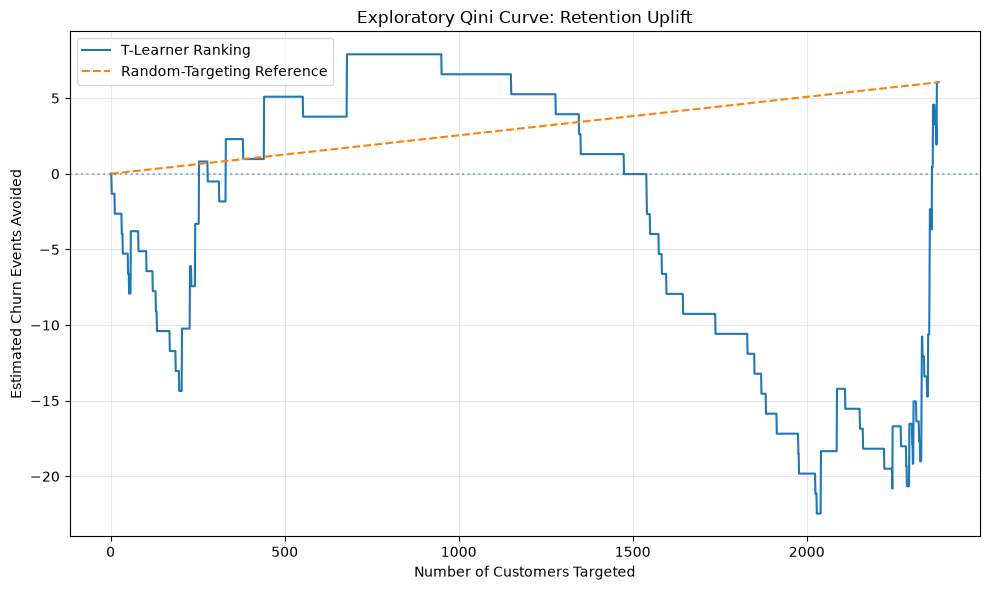

EXPLORATORY QINI EVALUATION
-------------------------------------------------------
Validation customers: 2379
Treatment proportion: 0.7575
Control proportion: 0.2425
Area above random reference: -14562.9692


In [10]:

# ============================================================
# NOTEBOOK 3 - STEP 1K: EXPLORATORY QINI CURVE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PREPARE THE VALIDATION DATA
# ------------------------------------------------------------

# Our 'evaluation' DataFrame was already sorted
# from highest to lowest estimated uplift.

qini_data = evaluation.copy().reset_index(drop=True)

# Calculate the overall treatment and control proportions.
p_treatment = (qini_data["Treatment"] == 1).mean()
p_control = 1 - p_treatment

# ------------------------------------------------------------
# 2. COMPUTE WEIGHTED CHURN CONTRIBUTIONS
# ------------------------------------------------------------

# Positive values represent contributions to estimated
# churn reduction under treatment.

qini_data["Contribution"] = np.where(
    qini_data["Treatment"] == 0,
    qini_data["Actual_Churn"] / p_control,
    -qini_data["Actual_Churn"] / p_treatment
)

# ------------------------------------------------------------
# 3. CALCULATE CUMULATIVE UPLIFT
# ------------------------------------------------------------

qini_data["Cumulative_Uplift"] = (
    qini_data["Contribution"].cumsum()
)

# Number of customers considered.
qini_data["Customers_Targeted"] = np.arange(
    1,
    len(qini_data) + 1
)

# ------------------------------------------------------------
# 4. CONSTRUCT RANDOM-TARGETING REFERENCE
# ------------------------------------------------------------

# Random targeting is represented by the straight line
# connecting zero and the final cumulative estimate.

total_uplift = qini_data["Cumulative_Uplift"].iloc[-1]

random_reference = (
    qini_data["Customers_Targeted"]
    / len(qini_data)
) * total_uplift

# ------------------------------------------------------------
# 5. PLOT THE CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    qini_data["Customers_Targeted"],
    qini_data["Cumulative_Uplift"],
    label="T-Learner Ranking"
)

plt.plot(
    qini_data["Customers_Targeted"],
    random_reference,
    linestyle="--",
    label="Random-Targeting Reference"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.title("Exploratory Qini Curve: Retention Uplift")
plt.xlabel("Number of Customers Targeted")
plt.ylabel("Estimated Churn Events Avoided")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CALCULATE AREA ABOVE RANDOM REFERENCE
# ------------------------------------------------------------

qini_area = np.trapezoid(
    qini_data["Cumulative_Uplift"] - random_reference,
    qini_data["Customers_Targeted"]
)

print("EXPLORATORY QINI EVALUATION")
print("-" * 55)

print("Validation customers:", len(qini_data))

print("Treatment proportion:", round(p_treatment, 4))

print("Control proportion:", round(p_control, 4))

print("Area above random reference:", round(qini_area, 4))


## 11. Bootstrap uncertainty of the T-Learner curve

Stratified resampling of **the fixed validation predictions** assesses sampling variability only. The interval does not incorporate refitting variability or uncertainty about assignment design.

In [11]:

# ============================================================
# NOTEBOOK 3 - STEP 1L: BOOTSTRAP QINI UNCERTAINTY
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. DEFINE A FUNCTION TO CALCULATE OUR QINI-STYLE AREA
# ------------------------------------------------------------

def calculate_qini_area(data):

    # Sort from highest to lowest predicted uplift.
    ranked = data.sort_values(
        "Estimated_Uplift",
        ascending=False
    ).reset_index(drop=True)

    # Calculate treatment and control proportions.
    p_treat = (ranked["Treatment"] == 1).mean()
    p_control = 1 - p_treat

    # Calculate weighted observed churn contributions.
    contributions = np.where(
        ranked["Treatment"] == 0,
        ranked["Actual_Churn"] / p_control,
        -ranked["Actual_Churn"] / p_treat
    )

    # Cumulative estimated events avoided.
    cumulative = np.cumsum(contributions)

    # Customer positions.
    x = np.arange(1, len(ranked) + 1)

    # Random-targeting reference.
    random_line = (x / len(ranked)) * cumulative[-1]

    # Calculate area above random reference.
    area = np.trapezoid(
        cumulative - random_line,
        x
    )

    return area


# ------------------------------------------------------------
# 2. PREPARE THE VALIDATION DATA
# ------------------------------------------------------------

control_data = evaluation[
    evaluation["Treatment"] == 0
].copy()

treatment_data = evaluation[
    evaluation["Treatment"] == 1
].copy()

# ------------------------------------------------------------
# 3. PERFORM STRATIFIED BOOTSTRAP
# ------------------------------------------------------------

rng = np.random.default_rng(42)

n_bootstrap = 1000
bootstrap_areas = []

for _ in range(n_bootstrap):

    # Resample control customers with replacement.
    control_sample = control_data.iloc[
        rng.integers(
            0,
            len(control_data),
            size=len(control_data)
        )
    ]

    # Resample treated customers with replacement.
    treatment_sample = treatment_data.iloc[
        rng.integers(
            0,
            len(treatment_data),
            size=len(treatment_data)
        )
    ]

    # Combine both resampled groups.
    bootstrap_sample = pd.concat(
        [control_sample, treatment_sample],
        ignore_index=True
    )

    # Recalculate Qini-style area.
    bootstrap_areas.append(
        calculate_qini_area(bootstrap_sample)
    )

# ------------------------------------------------------------
# 4. CALCULATE BOOTSTRAP CONFIDENCE INTERVAL
# ------------------------------------------------------------

bootstrap_areas = np.asarray(bootstrap_areas)

ci_lower, ci_upper = np.percentile(
    bootstrap_areas,
    [2.5, 97.5]
)

original_area = calculate_qini_area(evaluation)

print("BOOTSTRAP QINI UNCERTAINTY ANALYSIS")
print("-" * 60)

print("Bootstrap replications:", n_bootstrap)

print(
    "Original Qini-style area:",
    round(original_area, 4)
)

print(
    "Bootstrap mean:",
    round(bootstrap_areas.mean(), 4)
)

print(
    "95% bootstrap interval:",
    (round(ci_lower, 4), round(ci_upper, 4))
)

print(
    "Proportion of bootstrap areas above zero:",
    round((bootstrap_areas > 0).mean(), 4)
)


BOOTSTRAP QINI UNCERTAINTY ANALYSIS
------------------------------------------------------------
Bootstrap replications: 1000
Original Qini-style area: -14562.9692
Bootstrap mean: -15006.6319
95% bootstrap interval: (np.float64(-57147.1305), np.float64(29520.1528))
Proportion of bootstrap areas above zero: 0.243


## 12. S-Learner: one outcome model

Fit one CatBoost using `X` and treatment `t`. Re-predict each validation customer with `t=0` and `t=1` to form an exploratory uplift score.

In [12]:

# ============================================================
# NOTEBOOK 3 - STEP 1M: TRAIN A CATBOOST S-LEARNER
# ============================================================

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# 1. PREPARE TRAINING AND VALIDATION FEATURES
# ------------------------------------------------------------

# Start with the same predictors used for our T-Learner.
X_train_s = X_train_uplift.copy()
X_val_s = X_val_uplift.copy()

# Add treatment assignment as a predictor.
X_train_s["t"] = t_train_prop.to_numpy()

# ------------------------------------------------------------
# 2. TRAIN A SINGLE CATBOOST MODEL
# ------------------------------------------------------------

s_learner_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=42,
    verbose=False
)

# Train using customer features, treatment, and churn outcome.
s_learner_model.fit(
    X_train_s,
    y_train_uplift,
    cat_features=categorical_features
)

print("S-Learner training completed.")

# ------------------------------------------------------------
# 3. CREATE TWO VERSIONS OF VALIDATION CUSTOMERS
# ------------------------------------------------------------

# Version 1: Assume no campaign assignment.
X_val_control_s = X_val_s.copy()
X_val_control_s["t"] = 0

# Version 2: Assume campaign assignment.
X_val_treatment_s = X_val_s.copy()
X_val_treatment_s["t"] = 1

# ------------------------------------------------------------
# 4. ESTIMATE POTENTIAL CHURN RISKS
# ------------------------------------------------------------

s_control_prob = s_learner_model.predict_proba(
    X_val_control_s
)[:, 1]

s_treatment_prob = s_learner_model.predict_proba(
    X_val_treatment_s
)[:, 1]

# ------------------------------------------------------------
# 5. CALCULATE ESTIMATED UPLIFT
# ------------------------------------------------------------

# Positive values indicate predicted churn reduction, not proven causal effects.
s_uplift_scores = s_control_prob - s_treatment_prob

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

s_learner_summary = pd.DataFrame({
    "Predicted_Churn_Control": s_control_prob,
    "Predicted_Churn_Treatment": s_treatment_prob,
    "Estimated_Uplift": s_uplift_scores
})

print("\nS-LEARNER UPLIFT SUMMARY")
print("-" * 55)

display(s_learner_summary.describe().round(4))

print(
    "\nCustomers with positive estimated uplift:",
    int((s_uplift_scores > 0).sum())
)

print(
    "Customers with negative estimated uplift:",
    int((s_uplift_scores < 0).sum())
)

print(
    "Customers with zero estimated uplift:",
    int((s_uplift_scores == 0).sum())
)

print(
    "Mean estimated uplift:",
    round(s_uplift_scores.mean(), 5)
)


S-Learner training completed.

S-LEARNER UPLIFT SUMMARY
-------------------------------------------------------


,Predicted_Churn_Control,Predicted_Churn_Treatment,Estimated_Uplift
count,2379.0000,2379.0000,2379.0000
mean,0.0143,0.0143,0.0000
std,0.0283,0.0282,0.0010
min,0.0001,0.0001,-0.0154
25%,0.0012,0.0012,-0.0001
50%,0.0034,0.0034,-0.0000
75%,0.0156,0.0155,0.0001
max,0.3579,0.3571,0.0175



Customers with positive estimated uplift: 1129
Customers with negative estimated uplift: 1250
Customers with zero estimated uplift: 0
Mean estimated uplift: 5e-05


### Supplement — Check predictions against observed churn

The earlier T- and S-Learner probability means appear much lower than observed churn rates. The following diagnostic compares each model’s **predicted risk under the actual assignment received** with the observed churn rate, separately within treatment groups. This is an outcome-model calibration check, **not** a causal effect validation.

In [ ]:
# ============================================================
# SUPPLEMENT: CHECK VALIDATION OUTCOME-PREDICTION CALIBRATION
# ============================================================
# This diagnostic compares each learner's prediction for the
# OBSERVED assignment with observed churn, within each group.
# It is descriptive; it does not validate individual causal effects.

from sklearn.metrics import brier_score_loss

observed_assignment = t_val_prop.to_numpy()
observed_outcome = y_val_uplift.to_numpy()

calibration_rows = []
for learner_name, p0, p1 in [
    ("T-Learner", p_control, p_treatment),
    ("S-Learner", s_control_prob, s_treatment_prob),
]:
    assigned_prob = np.where(observed_assignment == 1, p1, p0)
    for arm in (0, 1):
        mask = observed_assignment == arm
        calibration_rows.append({
            "Learner": learner_name,
            "Treatment": arm,
            "Customers": int(mask.sum()),
            "Observed_Churn_Rate": float(observed_outcome[mask].mean()),
            "Mean_Predicted_Risk": float(assigned_prob[mask].mean()),
            "Brier_Score": brier_score_loss(
                observed_outcome[mask], assigned_prob[mask]
            ),
        })
calibration_diagnostic = pd.DataFrame(calibration_rows)
print("VALIDATION OUTCOME-RISK DIAGNOSTIC (NOT CAUSAL VALIDATION)")
display(calibration_diagnostic.round(4))

## 13. Compare top-20% uplift selections

Use the same validation people and capacity for both approaches. Different models select different groups; raw differences do not demonstrate policy superiority.

In [13]:

# ============================================================
# NOTEBOOK 3 - STEP 1N: T-LEARNER VS S-LEARNER
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE THE VALIDATION DATA
# ------------------------------------------------------------

comparison_data = pd.DataFrame({
    "Treatment": t_val_prop.to_numpy(),
    "Actual_Churn": y_val_uplift.to_numpy(),
    "T_Learner_Uplift": uplift_scores,
    "S_Learner_Uplift": s_uplift_scores
})

# ------------------------------------------------------------
# 2. DEFINE A FUNCTION FOR TOP-K UPLIFT EVALUATION
# ------------------------------------------------------------

def evaluate_top_uplift(data, score_column, fraction=0.20):

    # Rank customers by predicted retention benefit.
    ranked = data.sort_values(
        score_column,
        ascending=False
    )

    # Select the highest-ranked customers.
    k = int(round(len(ranked) * fraction))

    selected = ranked.head(k)

    # Separate observed treatment groups.
    control = selected[selected["Treatment"] == 0]
    treated = selected[selected["Treatment"] == 1]

    # Calculate observed churn rates.
    control_rate = control["Actual_Churn"].mean()
    treatment_rate = treated["Actual_Churn"].mean()

    # Positive difference indicates lower churn in treatment.
    observed_uplift = (
        control_rate - treatment_rate
    ) * 100

    return {
        "Selected_Customers": k,
        "Control_N": len(control),
        "Treatment_N": len(treated),
        "Control_Churners": int(control["Actual_Churn"].sum()),
        "Treatment_Churners": int(treated["Actual_Churn"].sum()),
        "Observed_Uplift_pp": observed_uplift
    }

# ------------------------------------------------------------
# 3. EVALUATE BOTH MODELS
# ------------------------------------------------------------

results = []

for model_name, score_column in [
    ("T-Learner", "T_Learner_Uplift"),
    ("S-Learner", "S_Learner_Uplift")
]:

    metrics = evaluate_top_uplift(
        comparison_data,
        score_column,
        fraction=0.20
    )

    metrics["Model"] = model_name

    results.append(metrics)

# ------------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ------------------------------------------------------------

uplift_model_comparison = pd.DataFrame(results)

print("T-LEARNER VS S-LEARNER: TOP 20%")
print("-" * 65)

display(
    uplift_model_comparison[
        [
            "Model",
            "Selected_Customers",
            "Control_N",
            "Treatment_N",
            "Control_Churners",
            "Treatment_Churners",
            "Observed_Uplift_pp"
        ]
    ].round(4)
)


T-LEARNER VS S-LEARNER: TOP 20%
-----------------------------------------------------------------


,Model,Selected_Customers,Control_N,Treatment_N,Control_Churners,Treatment_Churners,Observed_Uplift_pp
0,T-Learner,476,94,382,7,18,2.7348
1,S-Learner,476,116,360,8,22,0.7854


## 14. Compare models across contact capacities

Evaluate cumulative top 20%, 40%, 60%, 80%, and 100% of the same validation population; these subsets overlap.

In [14]:

# ============================================================
# NOTEBOOK 3 - STEP 1O: UPLIFT COMPARISON ACROSS CAPACITIES
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. DEFINE TARGETING CAPACITIES
# ------------------------------------------------------------

fractions = [0.20, 0.40, 0.60, 0.80, 1.00]

comparison_results = []

# ------------------------------------------------------------
# 2. EVALUATE EACH MODEL
# ------------------------------------------------------------

for model_name, score_column in [
    ("T-Learner", "T_Learner_Uplift"),
    ("S-Learner", "S_Learner_Uplift")
]:

    for fraction in fractions:

        # Use the evaluation function created in Step 1N.
        result = evaluate_top_uplift(
            comparison_data,
            score_column,
            fraction=fraction
        )

        # Store the model and targeting capacity.
        result["Model"] = model_name
        result["Top_Percent"] = int(fraction * 100)

        comparison_results.append(result)

# ------------------------------------------------------------
# 3. DISPLAY COMPARISON
# ------------------------------------------------------------

capacity_comparison = pd.DataFrame(
    comparison_results
)

print("UPLIFT COMPARISON ACROSS TARGETING CAPACITIES")
print("-" * 65)

display(
    capacity_comparison[
        [
            "Model",
            "Top_Percent",
            "Selected_Customers",
            "Control_N",
            "Treatment_N",
            "Observed_Uplift_pp"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 4. CREATE A SIDE-BY-SIDE COMPARISON
# ------------------------------------------------------------

comparison_pivot = capacity_comparison.pivot(
    index="Top_Percent",
    columns="Model",
    values="Observed_Uplift_pp"
)

print("\nOBSERVED UPLIFT BY TARGETING CAPACITY")
print("-" * 65)

display(comparison_pivot.round(4))


UPLIFT COMPARISON ACROSS TARGETING CAPACITIES
-----------------------------------------------------------------


,Model,Top_Percent,Selected_Customers,Control_N,Treatment_N,Observed_Uplift_pp
0,T-Learner,20,476,94,382,2.7348
1,T-Learner,40,952,213,739,1.0495
2,T-Learner,60,1427,327,1100,0.2647
3,T-Learner,80,1903,442,1461,-0.7226
4,T-Learner,100,2379,577,1802,0.2544
5,S-Learner,20,476,116,360,0.7854
6,S-Learner,40,952,239,713,-0.1590
7,S-Learner,60,1427,354,1073,-0.4428
8,S-Learner,80,1903,468,1435,-0.3023
9,S-Learner,100,2379,577,1802,0.2544



OBSERVED UPLIFT BY TARGETING CAPACITY
-----------------------------------------------------------------


Model,S-Learner,T-Learner
Top_Percent,,
20,0.7854,2.7348
40,-0.1590,1.0495
60,-0.4428,0.2647
80,-0.3023,-0.7226
100,0.2544,0.2544


## 15. Compare Qini-style rankings

Use the identical exploratory area definition for both models so observed comparisons are internally consistent.

In [15]:

# ============================================================
# NOTEBOOK 3 - STEP 1P: COMPARE UPLIFT RANKING PERFORMANCE
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. USE THE FUNCTION FROM STEP 1L
# ------------------------------------------------------------

# calculate_qini_area() computes the area above the
# random-targeting reference using observed churn outcomes.

# ------------------------------------------------------------
# 2. EVALUATE BOTH MODELS
# ------------------------------------------------------------

qini_comparison_results = []

for model_name, score_column in [
    ("T-Learner", "T_Learner_Uplift"),
    ("S-Learner", "S_Learner_Uplift")
]:

    # Rename the model's score column to the name
    # required by our existing Qini function.
    model_data = comparison_data[
        ["Treatment", "Actual_Churn", score_column]
    ].copy()

    model_data = model_data.rename(
        columns={score_column: "Estimated_Uplift"}
    )

    # Calculate Qini-style area.
    qini_area = calculate_qini_area(model_data)

    qini_comparison_results.append({
        "Model": model_name,
        "Qini_Style_Area": qini_area
    })

# ------------------------------------------------------------
# 3. DISPLAY COMPARISON
# ------------------------------------------------------------

qini_model_comparison = pd.DataFrame(
    qini_comparison_results
)

print("T-LEARNER VS S-LEARNER: QINI COMPARISON")
print("-" * 60)

display(qini_model_comparison.round(4))


T-LEARNER VS S-LEARNER: QINI COMPARISON
------------------------------------------------------------


,Model,Qini_Style_Area
0,T-Learner,-14562.9692
1,S-Learner,-10214.4450


## 16. Paired bootstrap: S-Learner versus T-Learner

Resample identical customer records for both methods in each bootstrap iteration. Report a difference interval rather than inferring a winner from point estimates.

In [16]:

# ============================================================
# NOTEBOOK 3 - STEP 1Q: PAIRED BOOTSTRAP QINI COMPARISON
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE THE SAME VALIDATION CUSTOMERS FOR BOTH MODELS
# ------------------------------------------------------------

bootstrap_data = comparison_data.copy()

control_data = bootstrap_data[
    bootstrap_data["Treatment"] == 0
].reset_index(drop=True)

treatment_data = bootstrap_data[
    bootstrap_data["Treatment"] == 1
].reset_index(drop=True)

# ------------------------------------------------------------
# 2. DEFINE A FUNCTION TO CALCULATE EACH MODEL'S QINI AREA
# ------------------------------------------------------------

def get_model_qini(data, score_column):

    # Prepare the columns required by our Qini function.
    model_data = data[
        ["Treatment", "Actual_Churn", score_column]
    ].copy()

    model_data = model_data.rename(
        columns={score_column: "Estimated_Uplift"}
    )

    return calculate_qini_area(model_data)

# ------------------------------------------------------------
# 3. CALCULATE THE ORIGINAL MODEL DIFFERENCE
# ------------------------------------------------------------

original_t = get_model_qini(
    bootstrap_data, "T_Learner_Uplift"
)

original_s = get_model_qini(
    bootstrap_data, "S_Learner_Uplift"
)

original_difference = original_s - original_t

# ------------------------------------------------------------
# 4. PERFORM PAIRED STRATIFIED BOOTSTRAP
# ------------------------------------------------------------

rng = np.random.default_rng(42)

n_bootstrap = 1000
bootstrap_differences = []

for _ in range(n_bootstrap):

    # Resample control customers.
    control_indices = rng.integers(
        0, len(control_data), len(control_data)
    )

    control_sample = control_data.iloc[
        control_indices
    ]

    # Resample treatment customers.
    treatment_indices = rng.integers(
        0, len(treatment_data), len(treatment_data)
    )

    treatment_sample = treatment_data.iloc[
        treatment_indices
    ]

    # Combine the same selected records for both models.
    sample = pd.concat(
        [control_sample, treatment_sample],
        ignore_index=True
    )

    # Calculate both Qini areas on the same sample.
    t_area = get_model_qini(
        sample, "T_Learner_Uplift"
    )

    s_area = get_model_qini(
        sample, "S_Learner_Uplift"
    )

    # Positive difference favors S-Learner.
    bootstrap_differences.append(
        s_area - t_area
    )

# ------------------------------------------------------------
# 5. CALCULATE CONFIDENCE INTERVAL
# ------------------------------------------------------------

bootstrap_differences = np.asarray(
    bootstrap_differences
)

ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("PAIRED BOOTSTRAP: S-LEARNER MINUS T-LEARNER")
print("-" * 60)

print("Bootstrap replications:", n_bootstrap)

print(
    "Original Qini difference:",
    round(original_difference, 4)
)

print(
    "Bootstrap mean difference:",
    round(bootstrap_differences.mean(), 4)
)

print(
    "95% bootstrap interval:",
    (round(ci_lower, 4), round(ci_upper, 4))
)

print(
    "Proportion favoring S-Learner:",
    round((bootstrap_differences > 0).mean(), 4)
)


PAIRED BOOTSTRAP: S-LEARNER MINUS T-LEARNER
------------------------------------------------------------
Bootstrap replications: 1000
Original Qini difference: 4348.5241
Bootstrap mean difference: 3961.4356
95% bootstrap interval: (np.float64(-54884.5238), np.float64(65597.7804))
Proportion favoring S-Learner: 0.544


## 17. Benchmark: churn-risk targeting

Fit CatBoost on training labels without including `t`. This ranks likely churners, which is **not equivalent** to ranking people whose churn is preventable.

In [17]:

# ============================================================
# NOTEBOOK 3 - STEP 1R: RISK VS UPLIFT TARGETING
# ============================================================

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# 1. TRAIN A CHURN-RISK MODEL
# ------------------------------------------------------------

# Use the training data only.
# Do not include treatment assignment as a predictor.

risk_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=42,
    verbose=False
)

risk_model.fit(
    X_train_uplift,
    y_train_uplift,
    cat_features=categorical_features
)

# ------------------------------------------------------------
# 2. PREDICT CHURN RISK ON VALIDATION DATA
# ------------------------------------------------------------

risk_probabilities = risk_model.predict_proba(
    X_val_uplift
)[:, 1]

# ------------------------------------------------------------
# 3. PREPARE RANKING DATA
# ------------------------------------------------------------

strategy_comparison = comparison_data.copy()

strategy_comparison["Churn_Risk"] = risk_probabilities

# ------------------------------------------------------------
# 4. COMPARE TARGETING STRATEGIES
# ------------------------------------------------------------

strategy_results = []

for strategy_name, score_column in [
    ("Churn Risk", "Churn_Risk"),
    ("T-Learner Uplift", "T_Learner_Uplift"),
    ("S-Learner Uplift", "S_Learner_Uplift")
]:

    for fraction in [0.20, 0.40]:

        metrics = evaluate_top_uplift(
            strategy_comparison,
            score_column,
            fraction=fraction
        )

        strategy_results.append({
            "Strategy": strategy_name,
            "Top_Percent": int(fraction * 100),
            **metrics
        })

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

strategy_summary = pd.DataFrame(strategy_results)

print("CHURN-RISK VS UPLIFT TARGETING")
print("-" * 65)

display(
    strategy_summary[
        [
            "Strategy",
            "Top_Percent",
            "Selected_Customers",
            "Control_N",
            "Treatment_N",
            "Observed_Uplift_pp"
        ]
    ].round(4)
)


CHURN-RISK VS UPLIFT TARGETING
-----------------------------------------------------------------


,Strategy,Top_Percent,Selected_Customers,Control_N,Treatment_N,Observed_Uplift_pp
0,Churn Risk,20,476,128,348,2.3617
1,Churn Risk,40,952,232,720,1.8151
2,T-Learner Uplift,20,476,94,382,2.7348
3,T-Learner Uplift,40,952,213,739,1.0495
4,S-Learner Uplift,20,476,116,360,0.7854
5,S-Learner Uplift,40,952,239,713,-0.1590


## 18. Compare all three Qini-style rankings

Compare churn risk with S- and T-Learner rankings on the validation set using the same estimator.

In [18]:

# ============================================================
# NOTEBOOK 3 - STEP 1S: THREE-STRATEGY QINI COMPARISON
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. DEFINE THE THREE RANKING STRATEGIES
# ------------------------------------------------------------

strategies = {
    "Churn Risk": "Churn_Risk",
    "T-Learner": "T_Learner_Uplift",
    "S-Learner": "S_Learner_Uplift"
}

# ------------------------------------------------------------
# 2. CALCULATE QINI-STYLE AREA FOR EACH STRATEGY
# ------------------------------------------------------------

results = []

for strategy_name, score_column in strategies.items():

    # Use the same validation customers and observed outcomes.
    data = strategy_comparison[
        ["Treatment", "Actual_Churn", score_column]
    ].copy()

    # Rename score column for our existing Qini function.
    data = data.rename(
        columns={score_column: "Estimated_Uplift"}
    )

    # Calculate area above the random-targeting reference.
    area = calculate_qini_area(data)

    results.append({
        "Strategy": strategy_name,
        "Qini_Style_Area": area
    })

# ------------------------------------------------------------
# 3. DISPLAY THE RESULTS
# ------------------------------------------------------------

strategy_qini_comparison = pd.DataFrame(results)

strategy_qini_comparison = (
    strategy_qini_comparison
    .sort_values(
        "Qini_Style_Area",
        ascending=False
    )
)

print("THREE-STRATEGY QINI COMPARISON")
print("-" * 60)

display(strategy_qini_comparison.round(4))


THREE-STRATEGY QINI COMPARISON
------------------------------------------------------------


,Strategy,Qini_Style_Area
0,Churn Risk,27895.8283
2,S-Learner,-10214.4450
1,T-Learner,-14562.9692


## 19. Paired uncertainty: risk versus uplift rankings

Bootstrap area differences on the same sampled records for all strategies. Wide intervals indicate weak evidence of differential performance.

In [19]:

# ============================================================
# NOTEBOOK 3 - STEP 1T: PAIRED BOOTSTRAP STRATEGY COMPARISON
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE VALIDATION DATA
# ------------------------------------------------------------

# Use the same validation customers for all strategies.
data = strategy_comparison.copy()

control = data[data["Treatment"] == 0].reset_index(drop=True)
treated = data[data["Treatment"] == 1].reset_index(drop=True)

# Define the strategies to compare.
strategies = {
    "Churn Risk": "Churn_Risk",
    "T-Learner": "T_Learner_Uplift",
    "S-Learner": "S_Learner_Uplift"
}

# ------------------------------------------------------------
# 2. CALCULATE ORIGINAL QINI-STYLE AREAS
# ------------------------------------------------------------

original_areas = {
    name: get_model_qini(data, column)
    for name, column in strategies.items()
}

# ------------------------------------------------------------
# 3. PERFORM PAIRED STRATIFIED BOOTSTRAP
# ------------------------------------------------------------

rng = np.random.default_rng(42)

n_bootstrap = 1000

differences = {
    "Risk_minus_T": [],
    "Risk_minus_S": []
}

for _ in range(n_bootstrap):

    # Resample treatment and control groups separately.
    control_sample = control.iloc[
        rng.integers(0, len(control), len(control))
    ]

    treated_sample = treated.iloc[
        rng.integers(0, len(treated), len(treated))
    ]

    # Use identical resampled customers for every strategy.
    sample = pd.concat(
        [control_sample, treated_sample],
        ignore_index=True
    )

    # Calculate all three ranking areas.
    risk_area = get_model_qini(sample, "Churn_Risk")

    t_area = get_model_qini(sample, "T_Learner_Uplift")

    s_area = get_model_qini(sample, "S_Learner_Uplift")

    # Positive differences favor churn-risk targeting.
    differences["Risk_minus_T"].append(risk_area - t_area)
    differences["Risk_minus_S"].append(risk_area - s_area)

# ------------------------------------------------------------
# 4. SUMMARIZE UNCERTAINTY
# ------------------------------------------------------------

results = []

for comparison, values in differences.items():

    values = np.asarray(values)

    # Calculate the 95% percentile bootstrap interval.
    lower, upper = np.percentile(values, [2.5, 97.5])

    # Calculate the observed difference.
    if comparison == "Risk_minus_T":
        observed = (
            original_areas["Churn Risk"]
            - original_areas["T-Learner"]
        )
    else:
        observed = (
            original_areas["Churn Risk"]
            - original_areas["S-Learner"]
        )

    results.append({
        "Comparison": comparison,
        "Observed_Difference": observed,
        "Bootstrap_Mean": values.mean(),
        "CI_Lower": lower,
        "CI_Upper": upper,
        "Fraction_Positive": (values > 0).mean()
    })

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

bootstrap_strategy_comparison = pd.DataFrame(results)

print("PAIRED BOOTSTRAP: CHURN RISK VS UPLIFT MODELS")
print("-" * 65)

display(bootstrap_strategy_comparison.round(4))


PAIRED BOOTSTRAP: CHURN RISK VS UPLIFT MODELS
-----------------------------------------------------------------


,Comparison,Observed_Difference,Bootstrap_Mean,CI_Lower,CI_Upper,Fraction_Positive
0,Risk_minus_T,42458.7975,42741.4023,-23119.6365,111872.1928,0.894
1,Risk_minus_S,38110.2733,38779.9667,-17907.1890,99011.3512,0.879


### Qini methodology and uncertainty limitations

- The curve accumulates observed churn outcomes using weights equal to the **overall validation treatment/control fractions**, then measures area above the endpoint-to-origin line. This yields an **unnormalized Qini-style area**, not a universally standardized Qini coefficient.
- Use of these weights assumes the relevant assignment probabilities were constant across the analyzed cohort. **Campaign-level or customer-specific probabilities have not been independently verified.** Stratifying the sample on joint treatment/outcome labels does not supply missing design probabilities.
- Our bootstrap confidence intervals condition on the fitted scores and treat treatment arms as separately resampled. They **do not** capture learning/retraining variation, study-level randomization uncertainty, or unmeasured confounding.
- The 95% interval for the top-20% T-Learner observed difference includes zero. Paired bootstrap intervals comparing ranking strategies also include zero.
- Validation rankings were examined across multiple capacities and models. **Test results must not be used for retrospective model selection** or further tuning.
- A low predicted treatment effect or a positive Qini score is not proof of a positive causal intervention effect. Churn-risk ranking and treatment-benefit ranking address different business objectives.


## 20. Locked held-out test assessment

Run once after validation development. Do not choose a strategy or adjust models because one happened to score best on this test split.

In [21]:

# ============================================================
# NOTEBOOK 3 - STEP 1V: FINAL HELD-OUT TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE THE ORIGINAL TEST DATA
# ------------------------------------------------------------

# Use the protected test split created in Step 1D.
X_test_uplift = X_test_prop.copy()

# Recover the corresponding churn outcomes.
y_test_uplift = y.loc[X_test_uplift.index]
t_test_uplift = t_test_prop.loc[X_test_uplift.index]

# Prepare categorical columns exactly as during training.
for column in categorical_features:
    X_test_uplift[column] = (
        X_test_uplift[column].astype(str)
    )

print("FINAL TEST DATA")
print("-" * 55)
print("Test customers:", len(X_test_uplift))
print("Control customers:", int((t_test_uplift == 0).sum()))
print("Treated customers:", int((t_test_uplift == 1).sum()))
print("Actual churners:", int(y_test_uplift.sum()))

# ------------------------------------------------------------
# 2. GENERATE T-LEARNER UPLIFT ESTIMATES
# ------------------------------------------------------------

# No additional training takes place here.
test_p_control = control_model.predict_proba(
    X_test_uplift
)[:, 1]

test_p_treatment = treatment_model.predict_proba(
    X_test_uplift
)[:, 1]

test_t_uplift = test_p_control - test_p_treatment

# ------------------------------------------------------------
# 3. GENERATE S-LEARNER UPLIFT ESTIMATES
# ------------------------------------------------------------

X_test_s0 = X_test_uplift.copy()
X_test_s1 = X_test_uplift.copy()

# Evaluate the same customer under both assignments.
X_test_s0["t"] = 0
X_test_s1["t"] = 1

test_s_uplift = (
    s_learner_model.predict_proba(X_test_s0)[:, 1]
    - s_learner_model.predict_proba(X_test_s1)[:, 1]
)

# ------------------------------------------------------------
# 4. GENERATE CHURN-RISK SCORES
# ------------------------------------------------------------

test_risk = risk_model.predict_proba(
    X_test_uplift
)[:, 1]

# ------------------------------------------------------------
# 5. COMBINE THE THREE RANKINGS
# ------------------------------------------------------------

final_test_data = pd.DataFrame({
    "Treatment": t_test_uplift.to_numpy(),
    "Actual_Churn": y_test_uplift.to_numpy(),
    "Churn_Risk": test_risk,
    "T_Learner_Uplift": test_t_uplift,
    "S_Learner_Uplift": test_s_uplift
})

# ------------------------------------------------------------
# 6. EVALUATE THE LOCKED STRATEGIES
# ------------------------------------------------------------

# This function was created in Step 1Q.
# It uses the same Qini-style definition for all strategies.

strategies = {
    "Churn Risk": "Churn_Risk",
    "T-Learner": "T_Learner_Uplift",
    "S-Learner": "S_Learner_Uplift"
}

final_results = []

for name, column in strategies.items():

    # Calculate the full-ranking Qini-style area.
    qini_area = get_model_qini(
        final_test_data,
        column
    )

    # Evaluate the top 20% at a fixed targeting capacity.
    top20 = evaluate_top_uplift(
        final_test_data,
        column,
        fraction=0.20
    )

    final_results.append({
        "Strategy": name,
        "Qini_Style_Area": qini_area,
        "Top20_Customers": top20["Selected_Customers"],
        "Top20_Control_N": top20["Control_N"],
        "Top20_Treatment_N": top20["Treatment_N"],
        "Top20_Observed_Difference_pp":
            top20["Observed_Uplift_pp"]
    })

# ------------------------------------------------------------
# 7. DISPLAY THE FINAL COMPARISON
# ------------------------------------------------------------

final_test_summary = pd.DataFrame(final_results)

print("\nFINAL HELD-OUT UPLIFT COMPARISON")
print("-" * 65)

display(final_test_summary.round(4))


FINAL TEST DATA
-------------------------------------------------------
Test customers: 2380
Control customers: 578
Treated customers: 1802
Actual churners: 81

FINAL HELD-OUT UPLIFT COMPARISON
-----------------------------------------------------------------


,Strategy,Qini_Style_Area,Top20_Customers,Top20_Control_N,Top20_Treatment_N,Top20_Observed_Difference_pp
0,Churn Risk,12902.2213,476,118,358,2.6749
1,T-Learner,11521.7607,476,97,379,2.7800
2,S-Learner,37129.9516,476,115,361,6.0412


## 21. Findings, business implications, and limitations

### Research objective and methods

Investigate whether a retention-campaign **assignment** could be targeted more effectively using model-estimated treatment-effect rankings than by ordinary churn-risk ranking. The analysis assessed numerical/categorical balance, propensity classification and overlap; trained CatBoost T- and S-Learners and a CatBoost churn-risk benchmark; compared observed outcomes in ranking subsets; and assessed an exploratory Qini-style area with stratified paired bootstrap uncertainty.

### Main results

The dataset contains **11,896 customers** (9,010 treated; 2,886 controls) with **408 churn events**. Overall observed churn was about **3.36% in treatment** versus **3.64% in control**, a small nonsignificant difference. The training split contains only **63 churn events among 1,731 control customers**, limiting estimation precision.

| Targeting strategy | Validation Qini-style area | Test Qini-style area | Test top-20% observed churn difference |
|---|---:|---:|---:|
| Churn-risk CatBoost | +27,895.83 | +12,902.22 | +2.67 pp |
| T-Learner | −14,562.97 | +11,521.76 | +2.78 pp |
| S-Learner | −10,214.45 | +37,129.95 | +6.04 pp |

The T-Learner top-20% validation observed difference was **+2.73 pp**, but its Newcombe 95% interval was **−1.87 to +10.07 pp**. The T-Learner's validation Qini-style area had a wide bootstrap interval spanning zero (**−57,147 to +29,520**). Paired intervals for comparisons among S-, T-, and churn-risk ranking approaches also included zero.

The **S-Learner scored highest on the held-out test subset**, despite poorer validation results. This test outcome is reported as observed and was **not** used to designate a new winner; rankings show appreciable sample-to-sample variability. The final test set is now consumed and cannot legitimately be reused for model selection or retuning.

### Model probability diagnostics

The T-Learner's mean predicted churn risks for control and treatment were **0.76%** and **1.14%**; the S-Learner's were approximately **1.43%** under either assignment. These scores are notably below the population's observed churn rates. This signals a need to inspect outcome-model calibration; the supplied notebook adds an **observed-assignment validation calibration diagnostic** but has not executed it here. It is inappropriate to interpret these scores as validated individual causal probabilities.

### Business interpretation

Churn-risk ranking identifies customers likely to leave. **Uplift ranking** instead attempts to identify customers whose outcome would change because of assignment. These strategies are not interchangeable. The available validation evidence does **not** establish that an uplift learner improves retention targeting over a churn-risk benchmark. A campaign should not be deployed solely on these scores without further verification and business cost assessment.

### Limitations

1. Rare events and unequal group sizes yield imprecise effect estimates.
2. Anonymization prevents substantive interpretation of individual PC/FACTOR predictors.
3. Observed balance and propensity overlap do not independently verify randomization or identify unmeasured selection effects.
4. Exact campaign-specific assignment probabilities are unavailable; using aggregate treatment fractions in the Qini-style estimator is a simplifying assumption.
5. Area values are unnormalized and bootstrap intervals exclude model-fitting uncertainty.
6. Model comparisons and subgroup selection on the validation split are exploratory and subject to selection variability.
7. Reported test metrics are descriptive, not conclusive evidence that one targeting strategy is causally better.
8. Campaign assignment is not necessarily customer contact or acceptance; results need not generalize beyond campaign-eligible customers.

### Conclusion and next steps

**Outcome:** The notebook demonstrates an end-to-end exploratory uplift modelling workflow and honestly reports mixed outcomes and large uncertainty. It does **not** establish a statistically reliable winning targeting policy. To substantiate causal/business claims, verify the actual campaign allocation procedure and treatment probabilities, evaluate across independent cohorts with sufficient churn outcomes, incorporate retraining uncertainty, and undertake prospective or independently held-out policy validation with contact costs.
